Iteration: 1 Best Fitness: 0.7431921463828982
Iteration: 2 Best Fitness: 0.7431921463828982
Iteration: 3 Best Fitness: 0.7431921463828982
Iteration: 4 Best Fitness: 0.6801227899943504
Iteration: 5 Best Fitness: 0.0819681180443816
Iteration: 6 Best Fitness: 0.0819681180443816
Iteration: 7 Best Fitness: 0.027143953521983365
Iteration: 8 Best Fitness: 0.027143953521983365
Iteration: 9 Best Fitness: 0.027143953521983365
Iteration: 10 Best Fitness: 0.005557818377332148
Iteration: 11 Best Fitness: 0.005557818377332148
Iteration: 12 Best Fitness: 0.005557818377332148
Iteration: 13 Best Fitness: 0.0004781743740110662
Iteration: 14 Best Fitness: 0.0004781743740110662
Iteration: 15 Best Fitness: 0.0004781743740110662
Iteration: 16 Best Fitness: 0.0004781743740110662
Iteration: 17 Best Fitness: 0.0004781743740110662
Iteration: 18 Best Fitness: 0.0004781743740110662
Iteration: 19 Best Fitness: 0.0004781743740110662
Iteration: 20 Best Fitness: 0.00041442106253694166
Iteration: 21 Best Fitness: 0.00

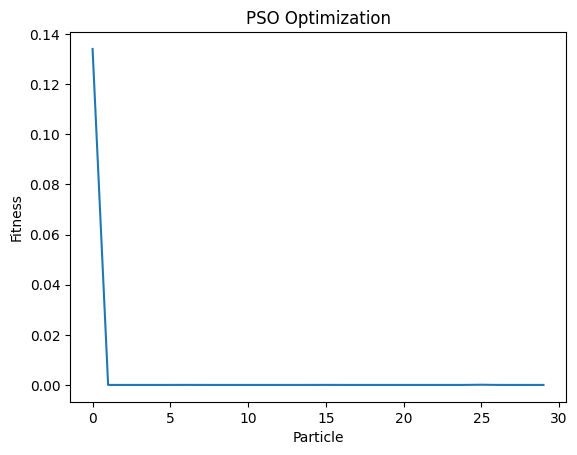

In [1]:

import numpy as np
import matplotlib.pyplot as plt

n_particles = 30
iterations = 100
dimensions = 2

w = 0.7
c1 = 1.5
c2 = 1.5

def fitness(position):
    return np.sum(position ** 2)

positions = np.random.uniform(-10, 10, (n_particles, dimensions))
velocities = np.random.uniform(-1, 1, (n_particles, dimensions))

pbest = positions.copy()
pbest_fitness = np.array([fitness(p) for p in positions])

gbest_index = np.argmin(pbest_fitness)
gbest = pbest[gbest_index].copy()

for iteration in range(iterations):

    for i in range(n_particles):

        r1 = np.random.random(dimensions)
        r2 = np.random.random(dimensions)

        velocities[i] = (
            w * velocities[i]
            + c1 * r1 * (pbest[i] - positions[i])
            + c2 * r2 * (gbest - positions[i])
        )

        positions[i] = positions[i] + velocities[i]

        current_fitness = fitness(positions[i])

        if current_fitness < pbest_fitness[i]:
            pbest[i] = positions[i].copy()
            pbest_fitness[i] = current_fitness

    gbest_index = np.argmin(pbest_fitness)
    gbest = pbest[gbest_index].copy()

    print("Iteration:", iteration + 1,
          "Best Fitness:", fitness(gbest))

print("Best Position:", gbest)
print("Minimum Value:", fitness(gbest))

plt.plot([fitness(p) for p in pbest])
plt.xlabel("Particle")
plt.ylabel("Fitness")
plt.title("PSO Optimization")
plt.show()
